In [1]:
# Welcome to your new notebook
# Type here in the cell editor to add code!

from pyspark.sql import functions as F
import pandas as pd

# Load hospital-level Gold data
df_hospital = spark.table(
    "gold_ed_hospital_quarterly"
)

# Select Toowoomba Hospital
df_forecast = (
    df_hospital
    .filter(F.col("facility_code") == 104)
    .select(
        "quarter_end_month",
        "total_attendances"
    )
    .orderBy("quarter_end_month")
)

# Convert to Pandas for forecasting
forecast_data = df_forecast.toPandas()

forecast_data["quarter_end_month"] = pd.to_datetime(
    forecast_data["quarter_end_month"]
)

print("Total observations:", len(forecast_data))
print("Missing values:")
print(forecast_data.isnull().sum())

display(forecast_data)


StatementMeta(, af2955cb-3217-450f-afa5-880b5e6bcc80, 3, Finished, Available, Finished, False)

Total observations: 11
Missing values:
quarter_end_month    0
total_attendances    0
dtype: int64


SynapseWidget(Synapse.DataFrame, 6c1f0fa6-cd9c-4db6-a433-940ac8f113c0)

StatementMeta(, af2955cb-3217-450f-afa5-880b5e6bcc80, 6, Finished, Available, Finished, False)

Naive forecasting results:


SynapseWidget(Synapse.DataFrame, 01a235f4-5cd4-454d-a8e5-589e7d30cc5a)

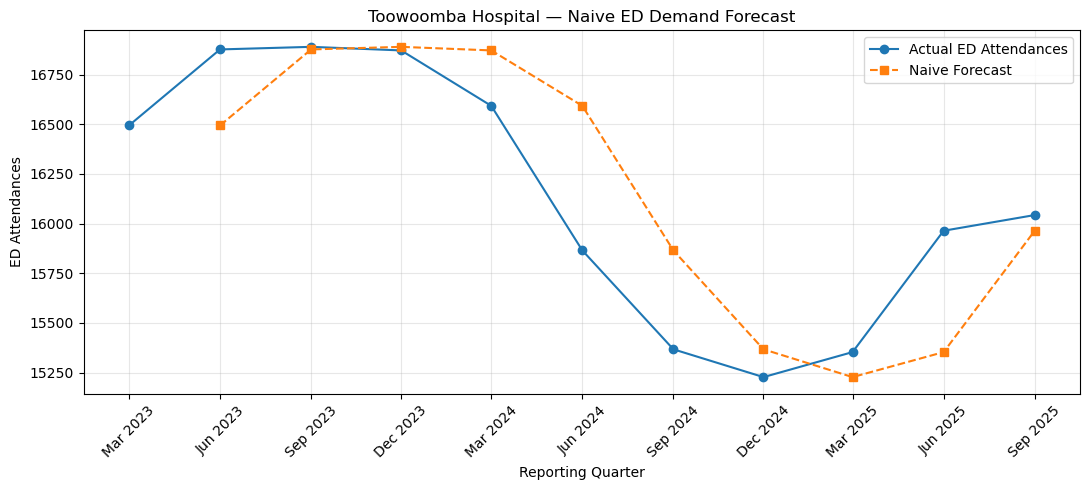

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Sort historical attendance records chronologically
forecast_data = forecast_data.sort_values(
    "quarter_end_month"
).reset_index(drop=True)

# Create one-quarter-ahead naive predictions
forecast_data["naive_forecast"] = (
    forecast_data["total_attendances"].shift(1)
)

# Calculate prediction errors
forecast_data["naive_error"] = (
    forecast_data["total_attendances"]
    - forecast_data["naive_forecast"]
)

print("Naive forecasting results:")
display(forecast_data)

# Visualise actual attendance and naive predictions
plt.figure(figsize=(11, 5))

plt.plot(
    forecast_data["quarter_end_month"],
    forecast_data["total_attendances"],
    marker="o",
    label="Actual ED Attendances"
)

plt.plot(
    forecast_data["quarter_end_month"],
    forecast_data["naive_forecast"],
    marker="s",
    linestyle="--",
    label="Naive Forecast"
)

plt.title("Toowoomba Hospital — Naive ED Demand Forecast")
plt.xlabel("Reporting Quarter")
plt.ylabel("ED Attendances")
plt.xticks(
    forecast_data["quarter_end_month"],
    forecast_data["quarter_end_month"].dt.strftime("%b %Y"),
    rotation=45
)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


StatementMeta(, af2955cb-3217-450f-afa5-880b5e6bcc80, 10, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 79335f54-7264-4621-b47b-1e9a4391aa16)

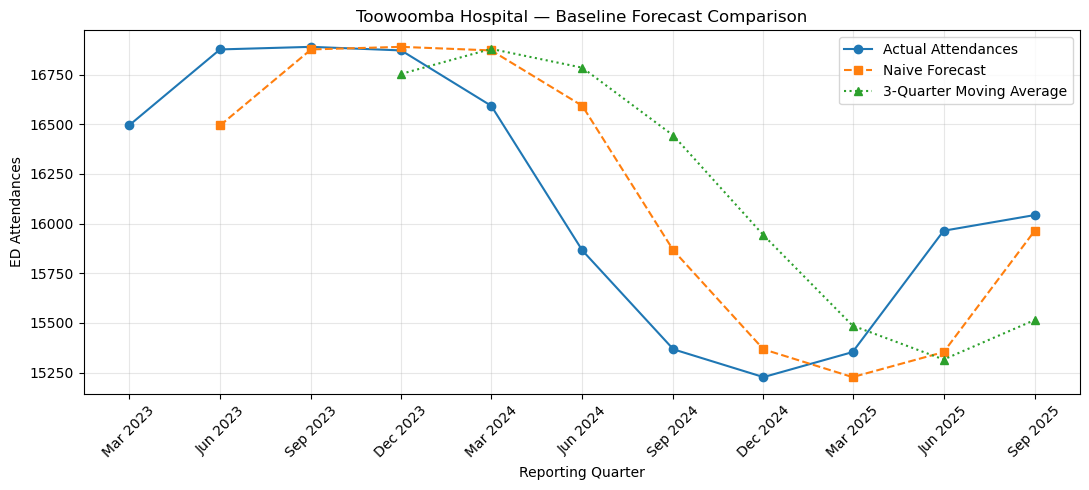

In [3]:
import matplotlib.pyplot as plt

# Three-quarter moving average forecast
# shift(1) prevents using the current quarter's actual value
forecast_data["ma3_forecast"] = (
    forecast_data["total_attendances"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

# Calculate prediction errors
forecast_data["ma3_error"] = (
    forecast_data["total_attendances"]
    - forecast_data["ma3_forecast"]
)

# Display the results
display(
    forecast_data[
        [
            "quarter_end_month",
            "total_attendances",
            "naive_forecast",
            "ma3_forecast"
        ]
    ]
)

# Visualise all three series
plt.figure(figsize=(11, 5))

plt.plot(
    forecast_data["quarter_end_month"],
    forecast_data["total_attendances"],
    marker="o",
    label="Actual Attendances"
)

plt.plot(
    forecast_data["quarter_end_month"],
    forecast_data["naive_forecast"],
    linestyle="--",
    marker="s",
    label="Naive Forecast"
)

plt.plot(
    forecast_data["quarter_end_month"],
    forecast_data["ma3_forecast"],
    linestyle=":",
    marker="^",
    label="3-Quarter Moving Average"
)

plt.title("Toowoomba Hospital — Baseline Forecast Comparison")
plt.xlabel("Reporting Quarter")
plt.ylabel("ED Attendances")
plt.xticks(
    forecast_data["quarter_end_month"],
    forecast_data["quarter_end_month"].dt.strftime("%b %Y"),
    rotation=45
)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [4]:
import numpy as np
import pandas as pd

# Use the same evaluation quarters for both models
df_test = forecast_data.dropna(
    subset=[
        "naive_forecast",
        "ma3_forecast"
    ]
).copy()

print("Evaluation quarters:", len(df_test))
print(
    "Evaluation period:",
    df_test["quarter_end_month"].min(),
    "to",
    df_test["quarter_end_month"].max()
)

actual = df_test["total_attendances"].to_numpy(
    dtype=float
)

models = {
    "Naive Forecast": df_test["naive_forecast"],
    "3-Quarter Moving Average": df_test["ma3_forecast"]
}

results = []

for model_name, predictions in models.items():

    predicted = predictions.to_numpy(dtype=float)
    errors = actual - predicted

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    mape = np.mean(
        np.abs(errors / actual)
    ) * 100

    results.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "MAPE (%)": round(mape, 2),
        "Evaluation Quarters": len(actual)
    })

df_evaluation = pd.DataFrame(results)

display(df_evaluation)


StatementMeta(, af2955cb-3217-450f-afa5-880b5e6bcc80, 12, Finished, Available, Finished, False)

Evaluation quarters: 8
Evaluation period: 2023-12-01 00:00:00 to 2025-09-01 00:00:00


SynapseWidget(Synapse.DataFrame, 3c046208-8d03-4b8b-923c-8de039a87e96)

In [5]:
import pandas as pd

# Identify the latest available quarter
latest_record = forecast_data.iloc[-1]

last_quarter = pd.to_datetime(
    latest_record["quarter_end_month"]
)

last_attendance = int(
    latest_record["total_attendances"]
)

# Forecast one quarter ahead
next_quarter = last_quarter + pd.DateOffset(months=3)

naive_prediction = last_attendance

print("Last observed quarter:", last_quarter.date())
print("Last observed attendances:", last_attendance)
print("Forecast quarter:", next_quarter.date())
print("Forecast ED attendances:", naive_prediction)


StatementMeta(, af2955cb-3217-450f-afa5-880b5e6bcc80, 13, Finished, Available, Finished, False)

Last observed quarter: 2025-09-01
Last observed attendances: 16043
Forecast quarter: 2025-12-01
Forecast ED attendances: 16043


In [6]:

import pandas as pd
from pyspark.sql import functions as F

# 1. Prepare model evaluation metrics
evaluation_output = df_evaluation.copy()
evaluation_output.columns = [
    "model_name",
    "mae",
    "rmse",
    "mape_pct",
    "evaluation_quarters"
]

evaluation_output["facility_code"] = 104

# Convert to Spark DataFrame
df_evaluation_spark = spark.createDataFrame(
    evaluation_output
)

# Save evaluation metrics
(
    df_evaluation_spark.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("gold_ed_forecast_evaluation")
)

# 2. Prepare future-quarter forecast
forecast_output = pd.DataFrame([{
    "facility_code": 104,
    "forecast_quarter": next_quarter.date(),
    "forecast_attendances": int(naive_prediction),
    "forecast_method": "Naive Forecast",
    "last_observed_quarter": last_quarter.date(),
    "training_observations": len(forecast_data)
}])

df_forecast_spark = spark.createDataFrame(
    forecast_output
)

# Save forecast
(
    df_forecast_spark.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("gold_ed_demand_forecast")
)

# 3. Validate saved tables
print(
    "Forecast evaluation records:",
    spark.table("gold_ed_forecast_evaluation").count()
)

print(
    "Demand forecast records:",
    spark.table("gold_ed_demand_forecast").count()
)

display(spark.table("gold_ed_forecast_evaluation"))
display(spark.table("gold_ed_demand_forecast"))


StatementMeta(, af2955cb-3217-450f-afa5-880b5e6bcc80, 14, Finished, Available, Finished, False)

Forecast evaluation records: 2
Demand forecast records: 1


SynapseWidget(Synapse.DataFrame, c8a9cc4e-59cf-4115-b0a6-6648184042b1)

SynapseWidget(Synapse.DataFrame, 6df5a9df-b6e0-42c6-aab6-d3dd2a1892fb)